# Optimised zero E-DAC power system

This notebook runs and presents the independently optimised **zero E-DAC** baseline. By default, nuclear, gas-CCS, medium-duration storage, and imports are all disabled, leaving renewable generation and hydrogen storage only. The optimisation logic lives in `src/zero_dac_optimisation.py`; this notebook is the reproducible results layer.

## 1. Configuration and system boundary

In [1]:
import json
import os
import sys
from dataclasses import replace
from pathlib import Path

import pandas as pd
from IPython.display import HTML, JSON, FileLink, Image, display

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src" / "zero_dac_optimisation.py").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "src" / "zero_dac_optimisation.py").exists():
    raise FileNotFoundError("Run this notebook from the project root or nbs directory.")
sys.path.insert(0, str(PROJECT_ROOT))

from src.zero_dac_optimisation import OptimisationConfig, optimise_zero_dac, save_results

RUN_OPTIMISATION = True
QUICK_MODE = os.environ.get("ZERO_DAC_NOTEBOOK_QUICK", "0") == "1"
OUTPUT_DIR = PROJECT_ROOT / "output" / "zero_dac_optimisation"

ENABLE_NUCLEAR = True
ENABLE_GAS_CCS = False
ENABLE_MEDIUM_STORAGE = False
ENABLE_IMPORTS = False

config = OptimisationConfig(
    enable_nuclear=ENABLE_NUCLEAR,
    enable_gas_ccs=ENABLE_GAS_CCS,
    enable_medium_storage=ENABLE_MEDIUM_STORAGE,
    enable_imports=ENABLE_IMPORTS,
    verbose=False,
)

# The environment switch is only for automated smoke testing. Normal notebook
# execution uses the complete paper-grade coarse and fine grids above.
if QUICK_MODE:
    config = replace(
        config,
        coarse_renewable_step_gw=40.0,
        coarse_electrolyser_step_gw=20.0,
        fine_renewable_span_gw=40.0,
        fine_electrolyser_span_gw=20.0,
        fine_renewable_step_gw=5.0,
        fine_electrolyser_step_gw=5.0,
        storage_tolerance_twh=1.0,
    )

display(
    pd.DataFrame({
        "Setting": ["E-DAC", "Nuclear", "Gas-CCS", "Medium storage", "Imports", "Hydrogen reserve", "Quick mode"],
        "Value": [
            "OFF (fixed at 0 GW)",
            ENABLE_NUCLEAR,
            ENABLE_GAS_CCS,
            ENABLE_MEDIUM_STORAGE,
            ENABLE_IMPORTS,
            f"{config.reserve_twh:g} TWh",
            QUICK_MODE,
        ],
    })
)

if RUN_OPTIMISATION:
    result = optimise_zero_dac(config)
    output_paths = save_results(result, OUTPUT_DIR)
else:
    expected = [
        OUTPUT_DIR / "optimal_system_summary.json",
        OUTPUT_DIR / "coarse_search_candidates.csv",
        OUTPUT_DIR / "fine_search_candidates.csv",
        OUTPUT_DIR / "optimal_daily_storage.csv",
        OUTPUT_DIR / "cost_surface.png",
        OUTPUT_DIR / "optimal_hydrogen_storage.png",
    ]
    missing = [path for path in expected if not path.exists()]
    if missing:
        raise FileNotFoundError(f"Missing optimisation outputs: {missing}")

print(f"Results directory: {OUTPUT_DIR}")

,Setting,Value
0,E-DAC,OFF (fixed at 0 GW)
1,Nuclear,True
2,Gas-CCS,False
3,Medium storage,False
4,Imports,False
5,Hydrogen reserve,20 TWh
6,Quick mode,False


Results directory: F:\UK-Energy-Modelling-Update-main-web\output\zero_dac_optimisation


## 2. Optimal-system summary

In [2]:
summary_path = OUTPUT_DIR / "optimal_system_summary.json"
summary = json.loads(summary_path.read_text(encoding="utf-8"))

display(JSON(summary))
print(json.dumps(summary, indent=2, ensure_ascii=False))

optimal = summary["optimal_system"]
summary_table = pd.DataFrame(
    [
        ("Renewable capacity", optimal["renewable_capacity_gw"], "GW"),
        ("Electrolyser power", optimal["electrolyser_power_gw"], "GW"),
        ("Hydrogen storage capacity", optimal["hydrogen_storage_capacity_twh"], "TWh"),
        ("Hydrogen generation power", optimal["hydrogen_generation_power_gw"], "GW"),
        ("E-DAC capacity", optimal["dac_capacity_gw"], "GW"),
        ("Minimum hydrogen storage", optimal["minimum_hydrogen_storage_twh"], "TWh"),
        ("Annual system cost", optimal["annual_system_cost_gbp"], "GBP/year"),
        ("Electricity-system cost", optimal["energy_cost_gbp_per_mwh"], "GBP/MWh"),
        ("Annual curtailed energy", optimal["annual_curtailed_energy_twh"], "TWh/year"),
        ("Cycle error", optimal["cycle_error_twh"], "TWh"),
    ],
    columns=["Metric", "Value", "Unit"],
)
display(summary_table.style.format({"Value": "{:,.3f}"}))
display(FileLink(summary_path))

<IPython.core.display.JSON object>

{
  "scenario": "zero_e_dac_optimised_power_system",
  "configuration": {
    "demand_mode": "seasonal",
    "capacity_factors_source": "era5_2024",
    "enable_nuclear": true,
    "enable_gas_ccs": false,
    "enable_medium_storage": false,
    "enable_imports": false,
    "reserve_twh": 20.0,
    "renewable_min_gw": 220.0,
    "renewable_max_gw": 500.0,
    "coarse_renewable_step_gw": 10.0,
    "electrolyser_min_gw": 20.0,
    "electrolyser_max_gw": 160.0,
    "coarse_electrolyser_step_gw": 5.0,
    "fine_renewable_span_gw": 10.0,
    "fine_electrolyser_span_gw": 10.0,
    "fine_renewable_step_gw": 1.0,
    "fine_electrolyser_step_gw": 1.0,
    "storage_max_twh": 500.0,
    "storage_tolerance_twh": 0.1,
    "cycle_tolerance_twh": 0.01,
    "max_cycle_iterations": 20,
    "hydrogen_generation_resolution_gw": 0.1,
    "verbose": false
  },
  "system_switches": {
    "e_dac": false,
    "nuclear": true,
    "gas_ccs": false,
    "medium_storage": false,
    "imports": false
  },
  "data

,Metric,Value,Unit
0,Renewable capacity,240.000,GW
1,Electrolyser power,48.000,GW
2,Hydrogen storage capacity,139.355,TWh
3,Hydrogen generation power,82.200,GW
4,E-DAC capacity,0.000,GW
5,Minimum hydrogen storage,20.034,TWh
6,Annual system cost,"71,070,727,211.957",GBP/year
7,Electricity-system cost,102.703,GBP/MWh
8,Annual curtailed energy,17.351,TWh/year
9,Cycle error,0.000,TWh


F:\UK-Energy-Modelling-Update-main-web\output\zero_dac_optimisation\optimal_system_summary.json

## 3. All coarse- and fine-search candidates

The scrollable tables below embed every row from both CSV files; infeasible candidates retain their failure reason.

In [3]:
coarse_path = OUTPUT_DIR / "coarse_search_candidates.csv"
fine_path = OUTPUT_DIR / "fine_search_candidates.csv"
coarse_candidates = pd.read_csv(coarse_path)
fine_candidates = pd.read_csv(fine_path)

candidate_overview = pd.DataFrame({
    "Search": ["Coarse", "Fine"],
    "Candidates": [len(coarse_candidates), len(fine_candidates)],
    "Feasible": [(coarse_candidates["status"] == "feasible").sum(), (fine_candidates["status"] == "feasible").sum()],
    "Minimum GBP/MWh": [coarse_candidates["energy_cost_gbp_per_mwh"].min(), fine_candidates["energy_cost_gbp_per_mwh"].min()],
})
display(candidate_overview)
display(FileLink(coarse_path))
display(FileLink(fine_path))


def display_scrollable_table(frame, title) -> None:
    table = frame.to_html(index=False, max_rows=None, border=0, float_format=lambda value: f"{value:,.4f}")
    display(HTML(f"<h3>{title}</h3><div style='max-height:520px; overflow:auto; border:1px solid #ddd'>{table}</div>"))


display_scrollable_table(coarse_candidates, "Complete coarse-search table")
display_scrollable_table(fine_candidates, "Complete fine-search table")

,Search,Candidates,Feasible,Minimum GBP/MWh
0,Coarse,841,779,102.727614
1,Fine,441,299,102.703363


F:\UK-Energy-Modelling-Update-main-web\output\zero_dac_optimisation\coarse_search_candidates.csv

F:\UK-Energy-Modelling-Update-main-web\output\zero_dac_optimisation\fine_search_candidates.csv

stage,status,failure_reason,reliable,renewable_capacity_gw,electrolyser_power_gw,hydrogen_storage_capacity_twh,hydrogen_generation_power_gw,dac_capacity_gw,minimum_hydrogen_storage_twh,initial_hydrogen_storage_twh,final_hydrogen_storage_twh,cycle_error_twh,cycle_iterations,annual_system_cost_gbp,energy_cost_gbp_per_mwh,annual_curtailed_energy_twh,curtailment_fraction,annual_gas_ccs_energy_twh,annual_interconnect_energy_twh,annual_medium_storage_input_twh,annual_dac_energy_twh
coarse,infeasible,unmet_demand,False,220.0000,20.0000,NaN,NaN,0.0000,NaN,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000
coarse,infeasible,unmet_demand,False,220.0000,25.0000,NaN,NaN,0.0000,NaN,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000
coarse,infeasible,unmet_demand,False,220.0000,30.0000,NaN,NaN,0.0000,NaN,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000
coarse,infeasible,unmet_demand,False,220.0000,35.0000,NaN,NaN,0.0000,NaN,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000
coarse,infeasible,unmet_demand,False,220.0000,40.0000,NaN,NaN,0.0000,NaN,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000
coarse,infeasible,unmet_demand,False,220.0000,45.0000,NaN,NaN,0.0000,NaN,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000
coarse,infeasible,unmet_demand,False,220.0000,50.0000,NaN,NaN,0.0000,NaN,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000
coarse,infeasible,unmet_demand,False,220.0000,55.0000,NaN,NaN,0.0000,NaN,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000
coarse,infeasible,unmet_demand,False,220.0000,60.0000,NaN,NaN,0.0000,NaN,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000
coarse,infeasible,unmet_demand,False,220.0000,65.0000,NaN,NaN,0.0000,NaN,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000


stage,status,failure_reason,reliable,renewable_capacity_gw,electrolyser_power_gw,hydrogen_storage_capacity_twh,hydrogen_generation_power_gw,dac_capacity_gw,minimum_hydrogen_storage_twh,initial_hydrogen_storage_twh,final_hydrogen_storage_twh,cycle_error_twh,cycle_iterations,annual_system_cost_gbp,energy_cost_gbp_per_mwh,annual_curtailed_energy_twh,curtailment_fraction,annual_gas_ccs_energy_twh,annual_interconnect_energy_twh,annual_medium_storage_input_twh,annual_dac_energy_twh
fine,infeasible,unmet_demand,False,230.0000,40.0000,NaN,NaN,0.0000,NaN,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000
fine,infeasible,unmet_demand,False,230.0000,41.0000,NaN,NaN,0.0000,NaN,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000
fine,infeasible,unmet_demand,False,230.0000,42.0000,NaN,NaN,0.0000,NaN,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000
fine,infeasible,unmet_demand,False,230.0000,43.0000,NaN,NaN,0.0000,NaN,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000
fine,infeasible,unmet_demand,False,230.0000,44.0000,NaN,NaN,0.0000,NaN,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000
fine,infeasible,unmet_demand,False,230.0000,45.0000,NaN,NaN,0.0000,NaN,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000
fine,infeasible,unmet_demand,False,230.0000,46.0000,NaN,NaN,0.0000,NaN,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000
fine,infeasible,unmet_demand,False,230.0000,47.0000,NaN,NaN,0.0000,NaN,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000
fine,infeasible,unmet_demand,False,230.0000,48.0000,NaN,NaN,0.0000,NaN,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000
fine,infeasible,unmet_demand,False,230.0000,49.0000,NaN,NaN,0.0000,NaN,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000


## 4. Daily optimal-system time series

In [4]:
daily_path = OUTPUT_DIR / "optimal_daily_storage.csv"
daily = pd.read_csv(
    daily_path,
    parse_dates=["date"],
    dtype_backend="numpy_nullable",
).convert_dtypes()
display(pd.DataFrame({"Column": daily.columns, "Data type": daily.dtypes.astype(str).to_numpy()}))
display(daily.head())
display(daily.tail())
display(daily.describe(include="all").T)
display(FileLink(daily_path))

,Column,Data type
0,date,datetime64[ns]
1,net_supply_twh,Float64
2,hydrogen_storage_twh,Float64
3,hydrogen_charge_input_twh,Float64
4,hydrogen_generation_twh,Float64
5,medium_storage_twh,Float64
6,gas_ccs_energy_twh,Float64
7,interconnect_energy_twh,Float64
8,curtailed_energy_twh,Float64
9,dac_energy_twh,Float64


,date,net_supply_twh,hydrogen_storage_twh,hydrogen_charge_input_twh,hydrogen_generation_twh,medium_storage_twh,gas_ccs_energy_twh,interconnect_energy_twh,curtailed_energy_twh,dac_energy_twh
0,1979-01-01,-0.442939,120.132527,0.0,0.442939,0.0,0.0,0.0,0.0,0.0
1,1979-01-02,-0.241955,119.692609,0.0,0.241955,0.0,0.0,0.0,0.0,0.0
2,1979-01-03,0.262612,119.886942,0.262612,0.0,0.0,0.0,0.0,0.0,0.0
3,1979-01-04,-0.047699,119.800216,0.0,0.047699,0.0,0.0,0.0,0.0,0.0
4,1979-01-05,-0.409915,119.054917,0.0,0.409915,0.0,0.0,0.0,0.0,0.0


,date,net_supply_twh,hydrogen_storage_twh,hydrogen_charge_input_twh,hydrogen_generation_twh,medium_storage_twh,gas_ccs_energy_twh,interconnect_energy_twh,curtailed_energy_twh,dac_energy_twh
14962,2019-12-27,0.51579,120.236443,0.51579,0.0,0.0,0.0,0.0,0.0,0.0
14963,2019-12-28,0.789465,120.820647,0.789465,0.0,0.0,0.0,0.0,0.0,0.0
14964,2019-12-29,0.861188,121.457926,0.861188,0.0,0.0,0.0,0.0,0.0,0.0
14965,2019-12-30,0.347026,121.714725,0.347026,0.0,0.0,0.0,0.0,0.0,0.0
14966,2019-12-31,-0.42727,120.93787,0.0,0.42727,0.0,0.0,0.0,0.0,0.0


,count,mean,min,25%,50%,75%,max,std
date,14967,1999-07-01 19:18:46.398075776,1979-01-01 00:00:00,1989-04-01 12:00:00,1999-07-01 00:00:00,2009-09-30 12:00:00,2019-12-31 00:00:00,NaN
net_supply_twh,14967.0,0.252787,-1.97178,-0.168895,0.281702,0.697069,1.864972,0.596324
hydrogen_storage_twh,14967.0,107.056127,20.033792,87.940341,110.235274,130.501271,139.355469,26.037192
hydrogen_charge_input_twh,14967.0,0.346122,0.0,0.0,0.201416,0.641852,1.152,0.384477
hydrogen_generation_twh,14967.0,0.140872,0.0,0.0,0.0,0.168895,1.97178,0.271209
medium_storage_twh,14967.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
gas_ccs_energy_twh,14967.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
interconnect_energy_twh,14967.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
curtailed_energy_twh,14967.0,0.047537,0.0,0.0,0.0,0.0,1.762295,0.184702
dac_energy_twh,14967.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


F:\UK-Energy-Modelling-Update-main-web\output\zero_dac_optimisation\optimal_daily_storage.csv

## 5. Cost surfaces and optimum

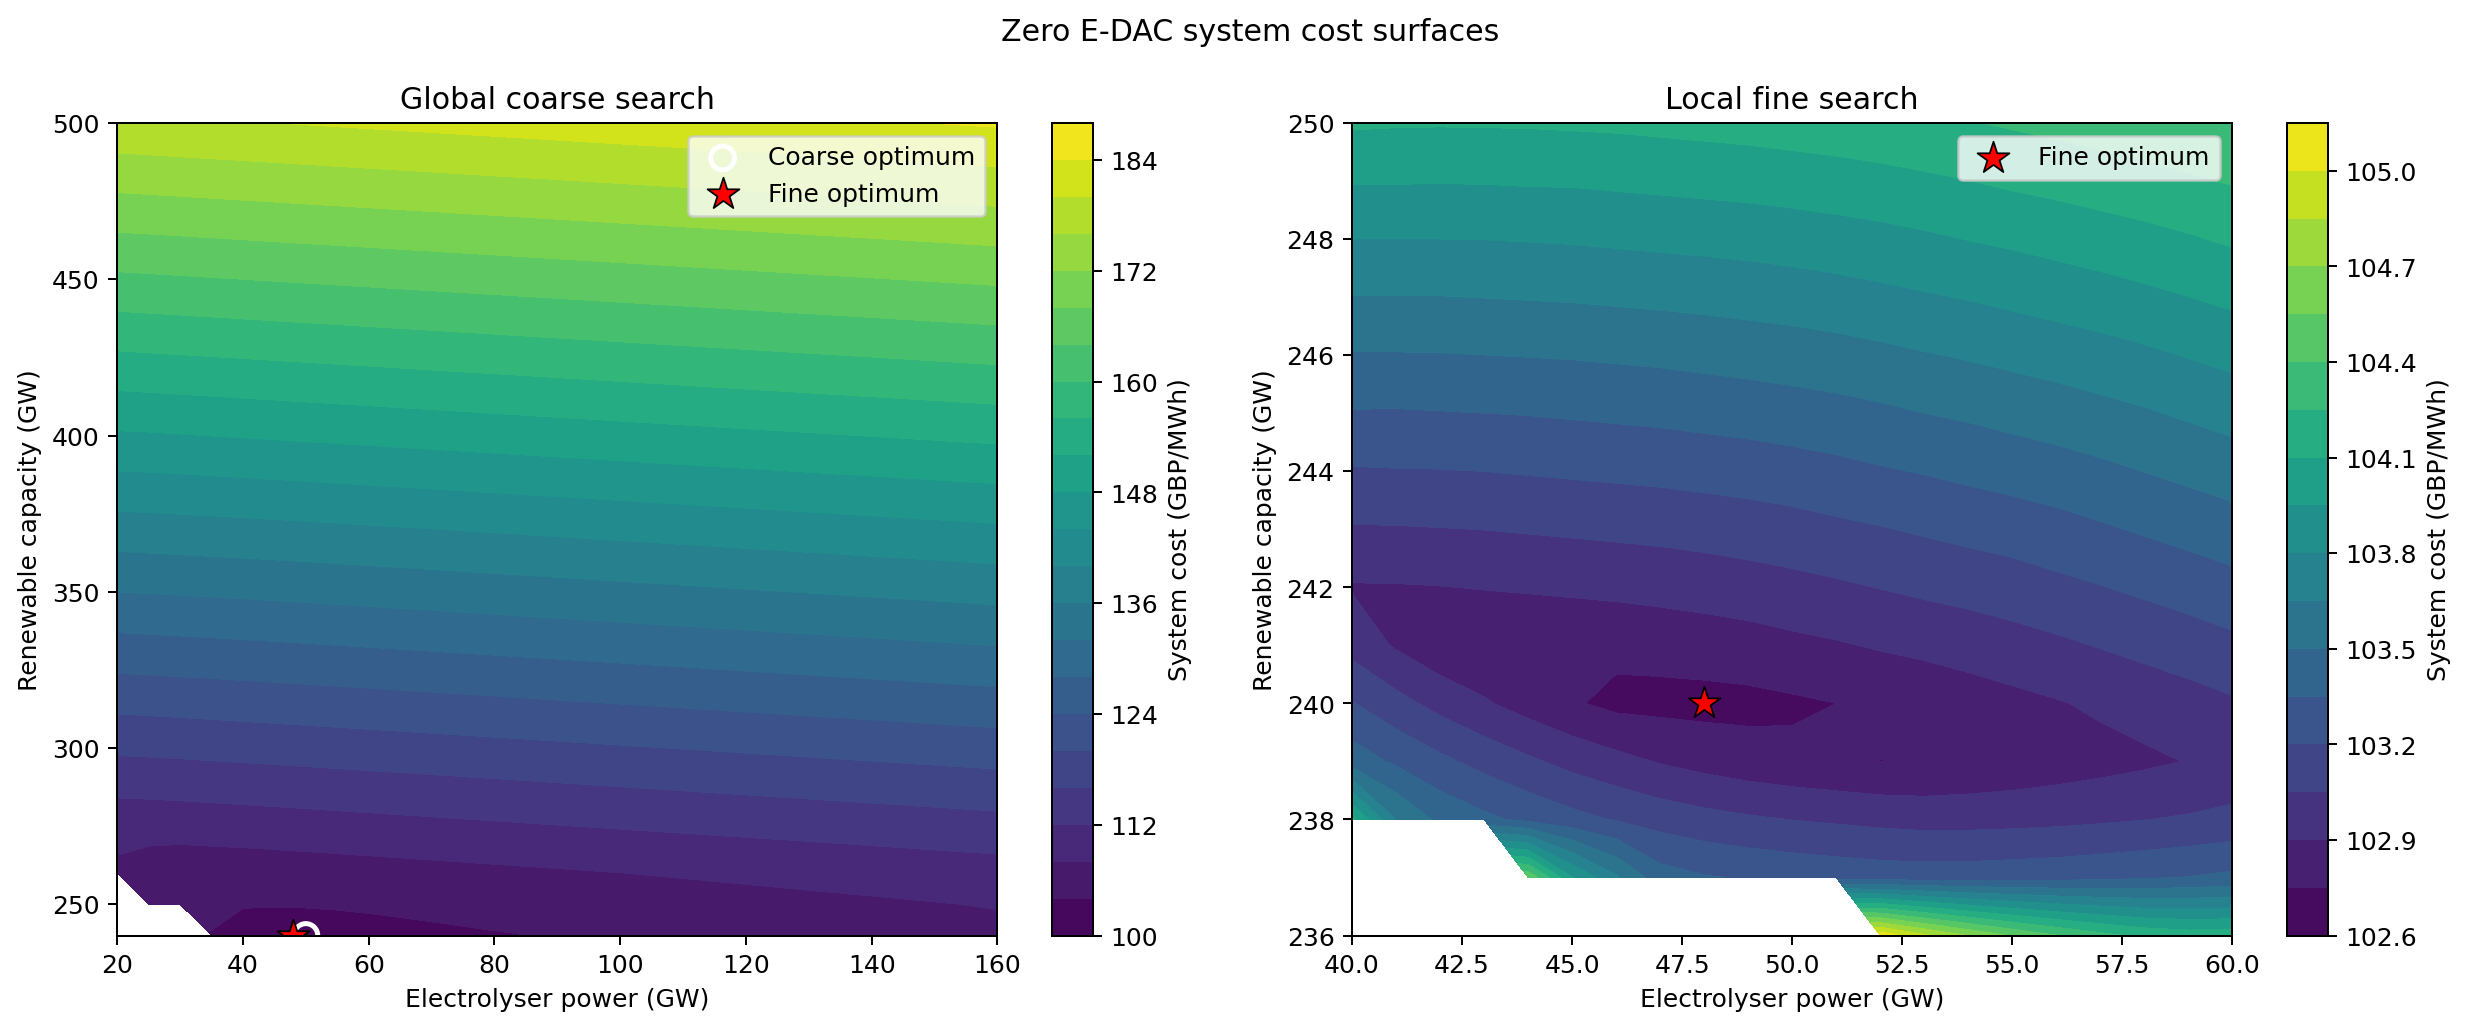

F:\UK-Energy-Modelling-Update-main-web\output\zero_dac_optimisation\cost_surface.png

In [5]:
cost_surface_path = OUTPUT_DIR / "cost_surface.png"
display(Image(filename=str(cost_surface_path)))
display(FileLink(cost_surface_path))

## 6. Optimal hydrogen-storage trajectory

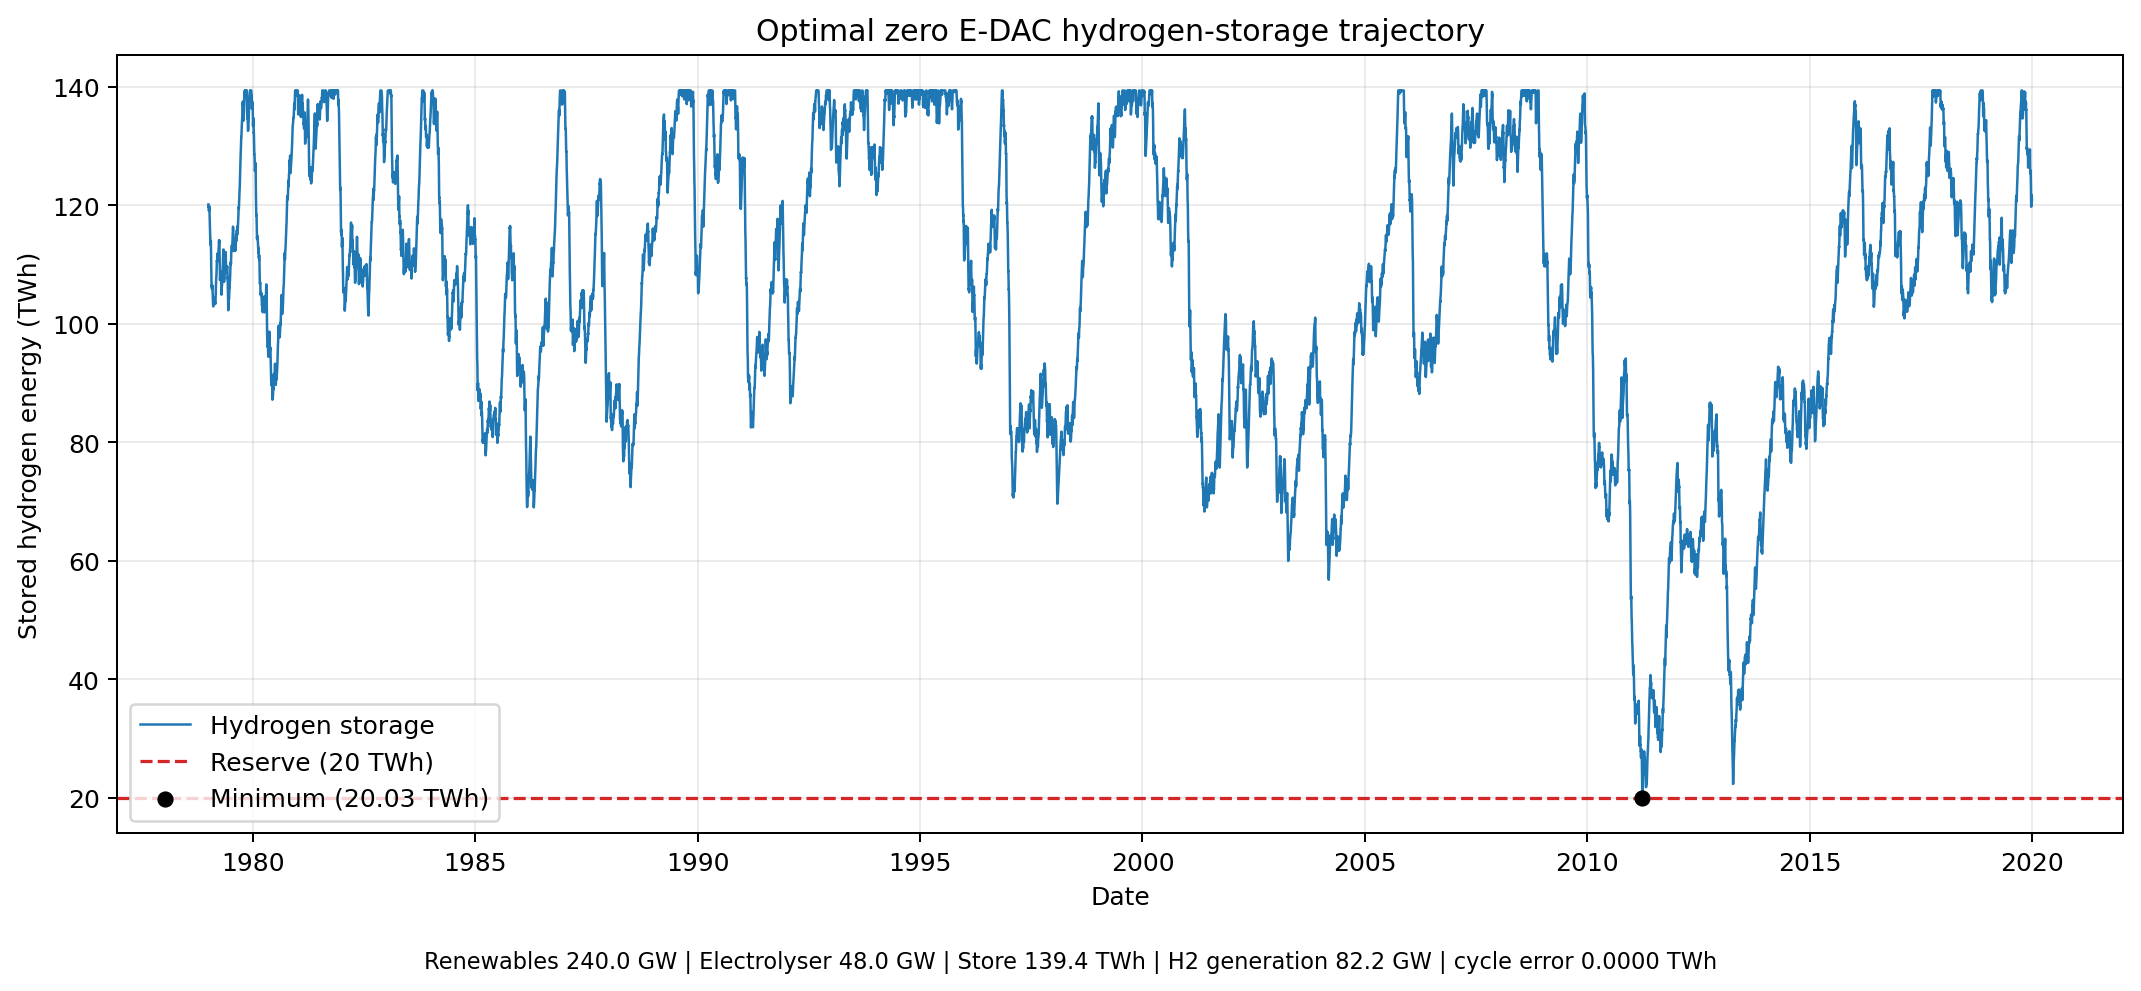

F:\UK-Energy-Modelling-Update-main-web\output\zero_dac_optimisation\optimal_hydrogen_storage.png

In [6]:
storage_plot_path = OUTPUT_DIR / "optimal_hydrogen_storage.png"
display(Image(filename=str(storage_plot_path)))
display(FileLink(storage_plot_path))